# QuantumXCT — ovarian co/mono culture (object-oriented, full analysis)

Single canonical OO notebook for the ovarian co-culture dataset (`dataset_co_mo2.h5ad`). Merges the single-pipeline walkthrough and the full benchmark suite:

1. **Single-pipeline demo** — encode → run → full figure report → save.
2. **Benchmark A** — search scopes: GRN+LR (`all`), GRN-only (`intra`), LR-only (`inter`).
3. **Angle-initialization study** — 0 vs. π/2 convergence.
4. **Benchmark B** — fair, budget-matched baselines (OT / Born / TN).
5. **L1 vs L2 encoding** — the scaling comparison.

Convention: mono-culture (Mo) = basal/initial, co-culture (Co) = target. Cancer cells = cell 1 (`gl_ct1`, q0..q3), fibroblasts = cell 2 (`gl_ct2`, q4..q6). Run from the `python/` folder.


In [1]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.sparse import issparse

from qxct import (QuantumXct, RunConfig, EncodingConfig, BackendConfig,
                  SearchConfig, OptimizerConfig, compare_angle_initializations)
from qxct.analysis import compare_scopes, plot_scope_report, compare_norms
from qxct.baselines import benchmark_budget_matched
from qxct.resources import curate_lr_pairs
from qxct.encoding import create_joint_histogram

np.random.seed(42)
OUT_DIR = 'results/ovarian_cocultured'
os.makedirs(OUT_DIR, exist_ok=True)

/home/ssromerogon/miniconda3/envs/qiskit-env/lib/python3.11/site-packages/scanpy/_utils/__init__.py:27: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version


/home/ssromerogon/miniconda3/envs/qiskit-env/lib/python3.11/site-packages/scanpy/__init__.py:36: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/home/ssromerogon/miniconda3/envs/qiskit-env/lib/python3.11/site-packages/scanpy/readwrite.py:15: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):


## 1. Load & preprocess


In [2]:
adata = sc.read_h5ad('dataset_co_mo2.h5ad')
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

AnnData object with n_obs × n_vars = 7890 × 13125
    obs: 'CellID', 'BatchID', 'ClusterID', 'CellType', 'CellCycle'
    uns: 'log1p'

## 2. Gene lists, cell-type names, and curated LR pairs
LR pairs are auto-curated from the merged Jin+Dimitrov database, intersected with the genes in this test (plotting only).


In [3]:
gl_ct1 = ['PDGFB', 'STAT3', 'HES4', 'TGFB1']   # cancer cells  -> q0..q3
gl_ct2 = ['PDGFRB', 'TGFBR1', 'TGFBR2']         # fibroblasts   -> q4..q6
gl_all = gl_ct1 + gl_ct2
ct1_name, ct2_name = 'Cancer Cells', 'Fibroblasts'
valid_lr_pairs = curate_lr_pairs(gl_all, resource_csv='LR_databases/Human-merged-Jin-Dimitrov-LR-pairs.csv')
print('curated LR pairs:', valid_lr_pairs)

[curate_lr_pairs] 3 LR pair(s) within the 7 test genes (resource='consensus'): [('PDGFB', 'PDGFRB'), ('TGFB1', 'TGFBR1'), ('TGFB1', 'TGFBR2')]
curated LR pairs: [('PDGFB', 'PDGFRB'), ('TGFB1', 'TGFBR1'), ('TGFB1', 'TGFBR2')]


## 3. Subset by BatchID and binarize (> 0)
Mono-culture (Mo) = basal; co-culture (Co) = target.


In [4]:
def _mat(a):
    return a.X.toarray() if issparse(a.X) else a.X

Xct1_co = _mat(adata[adata.obs['BatchID'] == 'Cancer Cells (Co)', gl_ct1])
Xct2_co = _mat(adata[adata.obs['BatchID'] == 'Fibroblasts (Co)',  gl_ct2])
Xct1_mo = _mat(adata[adata.obs['BatchID'] == 'Cancer Cells (Mo)', gl_ct1])
Xct2_mo = _mat(adata[adata.obs['BatchID'] == 'Fibroblasts (Mo)',  gl_ct2])

Xct1_binary_co = (Xct1_co > np.mean(Xct1_co, axis=0) * 0).astype(int)
Xct2_binary_co = (Xct2_co > np.mean(Xct2_co, axis=0) * 0).astype(int)
Xct1_binary_mo = (Xct1_mo > np.mean(Xct1_mo, axis=0) * 0).astype(int)
Xct2_binary_mo = (Xct2_mo > np.mean(Xct2_mo, axis=0) * 0).astype(int)

## 4. Joint histograms


In [5]:
joint_counts_ct1_co, _ = create_joint_histogram(Xct1_binary_co)
joint_counts_ct2_co, _ = create_joint_histogram(Xct2_binary_co)
joint_counts_ct1_mo, _ = create_joint_histogram(Xct1_binary_mo)
joint_counts_ct2_mo, _ = create_joint_histogram(Xct2_binary_mo)
print('CT1 co:', joint_counts_ct1_co)
print('CT2 co:', joint_counts_ct2_co)

CT1 co: Counter({'0110': 285, '0010': 207, '0100': 200, '0000': 178, '0111': 162, '0011': 84, '0101': 57, '0001': 45, '1110': 43, '1111': 43, '1100': 32, '1010': 26, '1000': 20, '1101': 13, '1011': 11, '1001': 8})
CT2 co: Counter({'000': 467, '001': 318, '100': 209, '101': 159, '010': 63, '011': 51, '110': 29, '111': 28})


## 5. Configuration
Shared by all sections. `threshold=0.005`, `search_mode='pos'`, 5000 shots, L1 encoding.


In [6]:
config = RunConfig(
    encoding=EncodingConfig(norm='l1'),
    backend=BackendConfig(shots=5000),
    search=SearchConfig(
        algorithm='multi_epoch', threshold=0.005, search_mode='pos',
        n_epochs=None, kl_tol=0.01, max_greedy_depth=30,
    ),
    optimizer=OptimizerConfig(method='COBYLA', initial_angle=np.pi / 2),
)

# Single-pipeline demo (GRN+LR)
Basic OO usage: encode the four histograms, run screen→search→optimize→analyze, print the result, draw the full figure report, and save.


In [7]:
qx = QuantumXct(config, gene_list=gl_all)
qx.encode(joint_counts_ct1_mo, joint_counts_ct2_mo, joint_counts_ct1_co, joint_counts_ct2_co)
result = qx.run()
print('Best topology :', result.topology)
print('CRX angles    :', [round(a, 3) for a in result.angles])
print('Final KL sum  :', round(result.kl_sum, 4))
result.contribution_df


--- CNOT Analysis (pos) ---
Max Signal: 0.0213
Candidates Found: 42 / 42
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 42
Initial KL divergence (baseline): 0.189151



--- Starting Epoch 1/42 (Addition) with CNOT: (1, 4) (KL: 0.156834) ---


    --> Found a better KL on this path: 0.038866 at depth 2 with added CNOT (4, 0)


    --> Found a better KL on this path: 0.029930 at depth 3 with added CNOT (0, 6)


    --> Found a better KL on this path: 0.027033 at depth 4 with added CNOT (5, 3)


...

    --> Found a better KL on this path: 0.034595 at depth 7 with added CNOT (5, 4)


  Epoch 42 best KL Sum: 0.034595

Final Result: Best sequence found has 4 CNOTs (KL: 0.027033).

Total search took: 361.02 seconds.

--- Starting CRX Angle Optimization (4 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 42   Least value of F = 0.02141055389247892   Constraint violation = 0.0
The corresponding X is:
[1.59870538 1.79491567 1.50285773 1.48163593]
The constraint value is:
[-1.59870538 -1.79491567 -1.50285773 -1.48163593 -1.54288727 -1.34667699
 -1.63873492 -1.65995672]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['1.5987', '1.7949', '1.5029', '1.4816']
CRX Angle Optimization took: 3.02 seconds

--- Comprehensive Interaction Network Analysis & Summary ---



--- Gate Contribution Analysis (Ablation Study) ---
   Step         Interaction CRX Angle (rad) KL Divergence KL Change Cumulative KL Reduction Isolated KL Isolated Reduction % Contribution % Isolated Contribution % of Total Reduction CRX Angle (deg)
0     0  Baseline (0 gates)             nan        0.1892    0.0000                  0.0000         nan             0.0000          0.00%                   0.00%               -0.00%            nan°
1     1     STAT3 -> PDGFRB          1.5987        0.1571   -0.0320                 -0.0320      0.1571             0.0320         16.92%                  16.92%               19.08%          91.60°
2     2     PDGFRB -> PDGFB          1.7949        0.0356   -0.1215                 -0.1535      0.0827             0.1065         64.24%                  56.29%               72.44%         102.84°
3     3     PDGFB -> TGFBR2          1.5029        0.0268   -0.0089                 -0.1624      0.1837             0.0054          4.69%              

,Step,Interaction,CRX Angle (rad),KL Divergence,KL Change,Cumulative KL Reduction,Isolated KL,Isolated Reduction,% Contribution,% Isolated Contribution,% of Total Reduction,CRX Angle (deg)
0,0,Baseline (0 gates),NaN,0.189151,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,-0.000000,NaN
1,1,STAT3 -> PDGFRB,1.598705,0.157149,-0.032002,-0.032002,0.157149,0.032002,16.918920,16.918920,19.078468,91.599071
2,2,PDGFRB -> PDGFB,1.794916,0.035636,-0.121512,-0.153515,0.082672,0.106479,64.240989,56.293318,72.440773,102.841092
3,3,PDGFB -> TGFBR2,1.502858,0.026761,-0.008875,-0.162390,0.183716,0.005435,4.691985,2.873189,5.290874,86.107405
4,4,TGFBR1 -> TGFB1,1.481636,0.021411,-0.005351,-0.167740,0.188420,0.000731,2.828812,0.386448,3.189884,84.891486


Saved histogram figure to results/ovarian_cocultured/single_pipeline/all_occupancy_3way.png


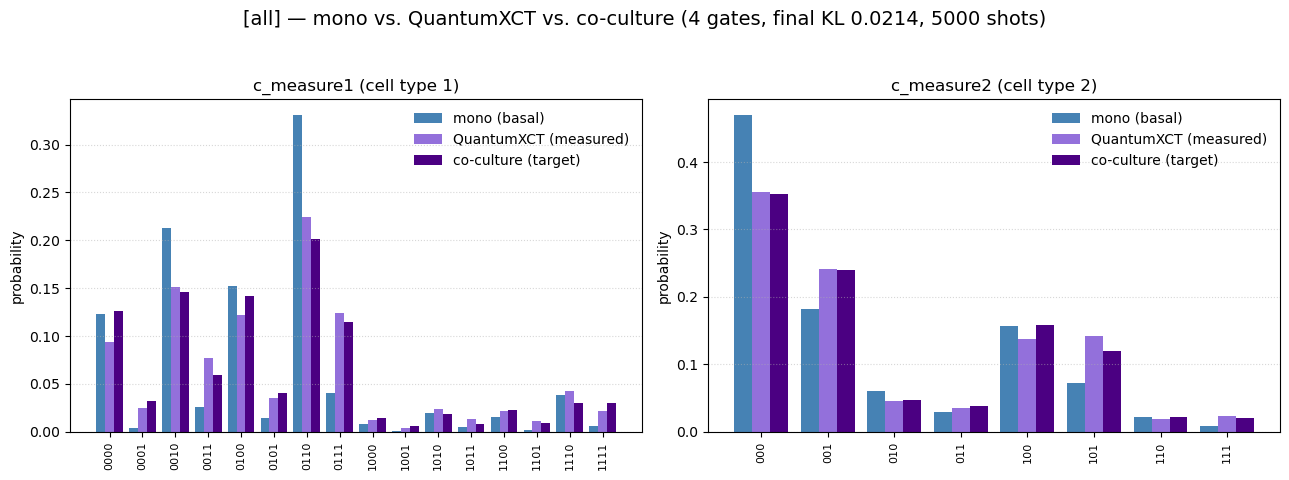


[all] optimized circuit (4 CRX gates):
              »
         q_0: »
              »
         q_1: »
              »
         q_2: »
              »
         q_3: »
              »
         q_4: »
              »
         q_5: »
              »
         q_6: »
              »
c_measure1: 4/»
              »
c_measure2: 3/»
              »
«              ┌──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐»
«         q_0: ┤0                                                                                                                                                 ├»
«              │                                                                                                                                                  │»
«         q_1: ┤1                                                                                                                                                


--- Running circuit for: [all] optimized ---


Counts for c_measure1: {'0101': 200, '0110': 1172, '0010': 708, '0001': 111, '0011': 390, '0000': 478, '0111': 667, '1110': 195, '0100': 593, '1000': 53, '1010': 107, '1101': 35, '1111': 112, '1011': 70, '1100': 94, '1001': 15}
Counts for c_measure2: {'001': 1148, '000': 1818, '100': 687, '101': 761, '010': 248, '011': 152, '111': 84, '110': 102}


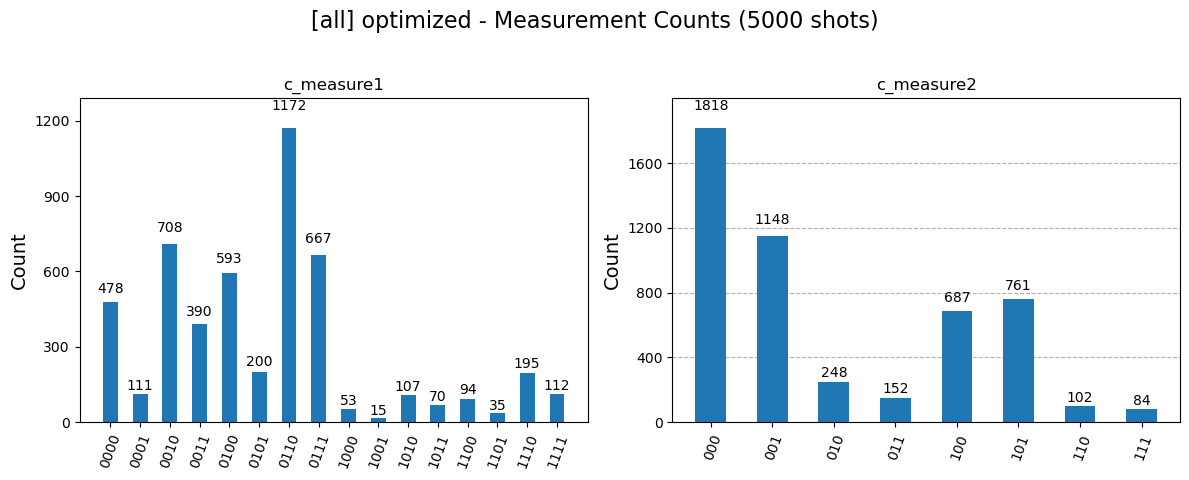

Histogram figure saved to results/ovarian_cocultured/single_pipeline/all_measurement_histograms.png

--- Comprehensive Interaction Network Analysis & Summary ---



--- Gate Contribution Analysis (Ablation Study) ---
   Step         Interaction CRX Angle (rad) KL Divergence KL Change Cumulative KL Reduction Isolated KL Isolated Reduction % Contribution % Isolated Contribution % of Total Reduction CRX Angle (deg)
0     0  Baseline (0 gates)             nan        0.1892    0.0000                  0.0000         nan             0.0000          0.00%                   0.00%               -0.00%            nan°
1     1     STAT3 -> PDGFRB          1.5987        0.1571   -0.0320                 -0.0320      0.1571             0.0320         16.92%                  16.92%               19.08%          91.60°
2     2     PDGFRB -> PDGFB          1.7949        0.0356   -0.1215                 -0.1535      0.0827             0.1065         64.24%                  56.29%               72.44%         102.84°
3     3     PDGFB -> TGFBR2          1.5029        0.0268   -0.0089                 -0.1624      0.1837             0.0054          4.69%              

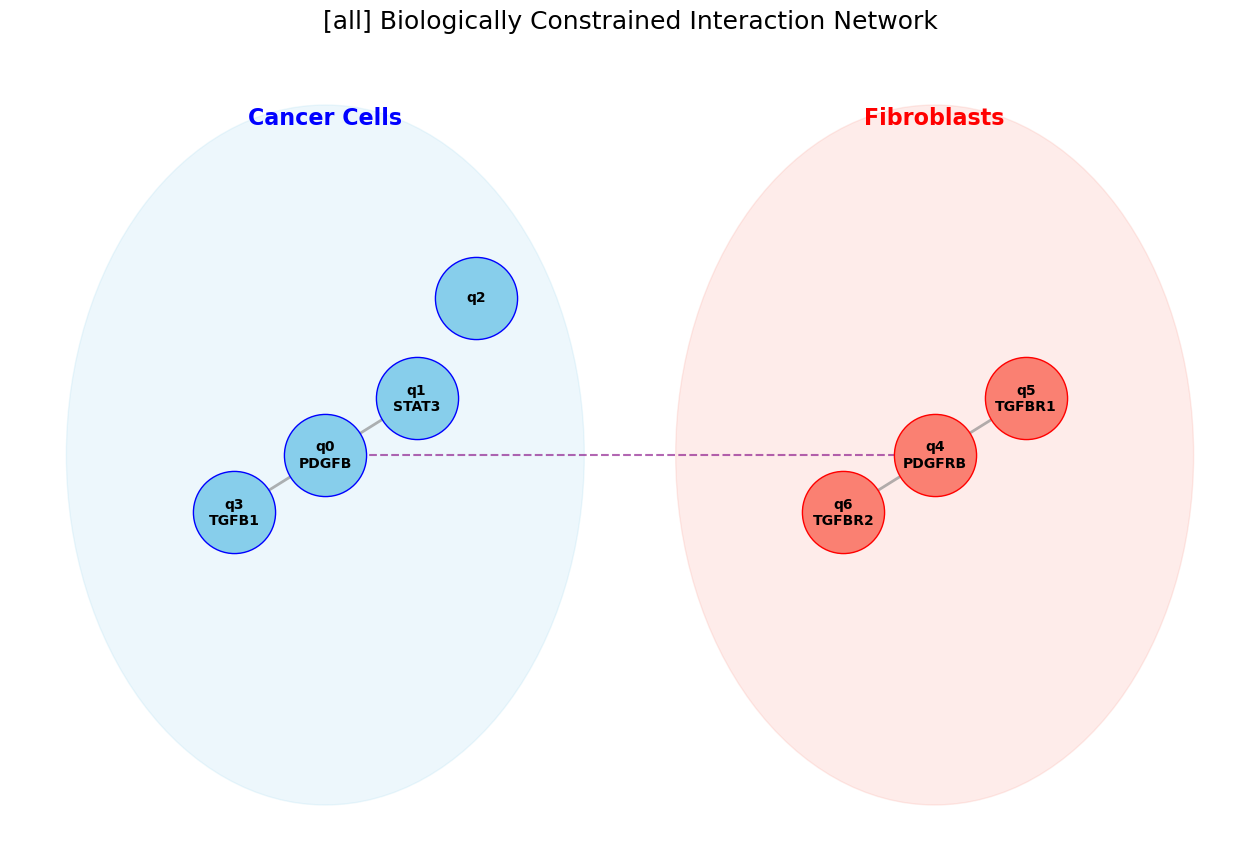

,Step,Interaction,CRX Angle (rad),KL Divergence,KL Change,Cumulative KL Reduction,Isolated KL,Isolated Reduction,% Contribution,% Isolated Contribution,% of Total Reduction,CRX Angle (deg)
0,0,Baseline (0 gates),NaN,0.189151,0.000000,0.000000,NaN,0.000000,0.000000,0.000000,-0.000000,NaN
1,1,STAT3 -> PDGFRB,1.598705,0.157149,-0.032002,-0.032002,0.157149,0.032002,16.918920,16.918920,19.078468,91.599071
2,2,PDGFRB -> PDGFB,1.794916,0.035636,-0.121512,-0.153515,0.082672,0.106479,64.240989,56.293318,72.440773,102.841092
3,3,PDGFB -> TGFBR2,1.502858,0.026761,-0.008875,-0.162390,0.183716,0.005435,4.691985,2.873189,5.290874,86.107405
4,4,TGFBR1 -> TGFB1,1.481636,0.021411,-0.005351,-0.167740,0.188420,0.000731,2.828812,0.386448,3.189884,84.891486


In [8]:
# Full figure report for the single run: 3-way occupancy, optimized circuit,
# measurement histograms, and the interaction network colored by cell type.
qx.plot_report(gl_ct1=gl_ct1, gl_ct2=gl_ct2, valid_lr_pairs=valid_lr_pairs,
               out_dir=os.path.join(OUT_DIR, 'single_pipeline'),
               ct1_name=ct1_name, ct2_name=ct2_name)

In [9]:
qx.save(os.path.join(OUT_DIR, 'run'), metadata={'dataset': 'dataset_co_mo2', 'search_mode': 'pos'})

Topology saved → results/ovarian_cocultured/run.json
Ablation results saved → results/ovarian_cocultured/run_ablation.csv


'results/ovarian_cocultured/run'

# Benchmark A — search scopes (GRN+LR / GRN-only / LR-only)


In [10]:
benchA = compare_scopes(
    config,
    joint_counts_ct1_mo, joint_counts_ct2_mo,
    joint_counts_ct1_co, joint_counts_ct2_co,
    gene_list=gl_all,
)
pd.set_option('display.float_format', lambda v: f'{v:.4f}')
benchA['summary'].to_csv(os.path.join(OUT_DIR, 'scope_summary.csv'), index=False)
benchA['summary']


--- CNOT Analysis (pos) ---
Max Signal: 0.0213
Candidates Found: 42 / 42
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 42
Initial KL divergence (baseline): 0.189151

--- Starting Epoch 1/42 (Addition) with CNOT: (1, 4) (KL: 0.156834) ---


    --> Found a better KL on this path: 0.038866 at depth 2 with added CNOT (4, 0)


    --> Found a better KL on this path: 0.029930 at depth 3 with added CNOT (0, 6)


    --> Found a better KL on this path: 0.027033 at depth 4 with added CNOT (5, 3)


  Epoch 1 best KL Sum: 0.027033
  --> Epoch 1 found a new overall best KL Sum: 0.027033

--- Starting Greedy CNOT Removal Search on Best Found Sequence ---
  Starting removal search with 4 CNOTs (KL Sum: 0.027033)


...

    --> Found a better KL on this path: 0.036013 at depth 4 with added CNOT (3, 6)


    --> Found a better KL on this path: 0.027827 at depth 5 with added CNOT (4, 1)


  Epoch 24 best KL Sum: 0.027827

Final Result: Best sequence found has 3 CNOTs (KL: 0.029930).

Total search took: 131.59 seconds.

--- Starting CRX Angle Optimization (3 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 32   Least value of F = 0.026628806095135283   Constraint violation = 0.0
The corresponding X is:
[1.42713763 1.77809498 1.46927236]
The constraint value is:
[-1.42713763 -1.77809498 -1.46927236 -1.71445503 -1.36349767 -1.67232029]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['1.4271', '1.7781', '1.4693']
CRX Angle Optimization took: 2.27 seconds


,Scope,Baseline KL,Final KL,KL Reduction,% Reduction,# Gates
0,GRN + LR,0.1892,0.0214,0.1677,88.6807,4
1,GRN only (intra),0.1892,0.0538,0.1354,71.5579,2
2,LR only (inter),0.1892,0.0266,0.1625,85.9219,3


[GRN+LR]  4 gates | baseline KL 0.1892 -> final KL 0.0214  (88.7% reduction)
Cumulative ablation reduction:
 Step        Interaction  CRX Angle (rad)  KL Divergence  KL Change  Cumulative KL Reduction  % of Baseline
    0 Baseline (0 gates)              NaN         0.1892     0.0000                   0.0000         0.0000
    1    STAT3 -> PDGFRB           1.5987         0.1571    -0.0320                   0.0320        16.9189
    2    PDGFRB -> PDGFB           1.7949         0.0356    -0.1215                   0.1535        81.1599
    3    PDGFB -> TGFBR2           1.5029         0.0268    -0.0089                   0.1624        85.8519
    4    TGFBR1 -> TGFB1           1.4816         0.0214    -0.0054                   0.1677        88.6807
Isolated / leave-one-out contribution:
           Gate  CRX Angle (rad)  Isolated KL  Isolated Reduction  LOO KL (without gate)  Marginal Contribution  % Marginal of Baseline
PDGFRB -> PDGFB           1.7949       0.0827              0.1065    

Saved histogram figure to results/ovarian_cocultured/all_occupancy_3way.png


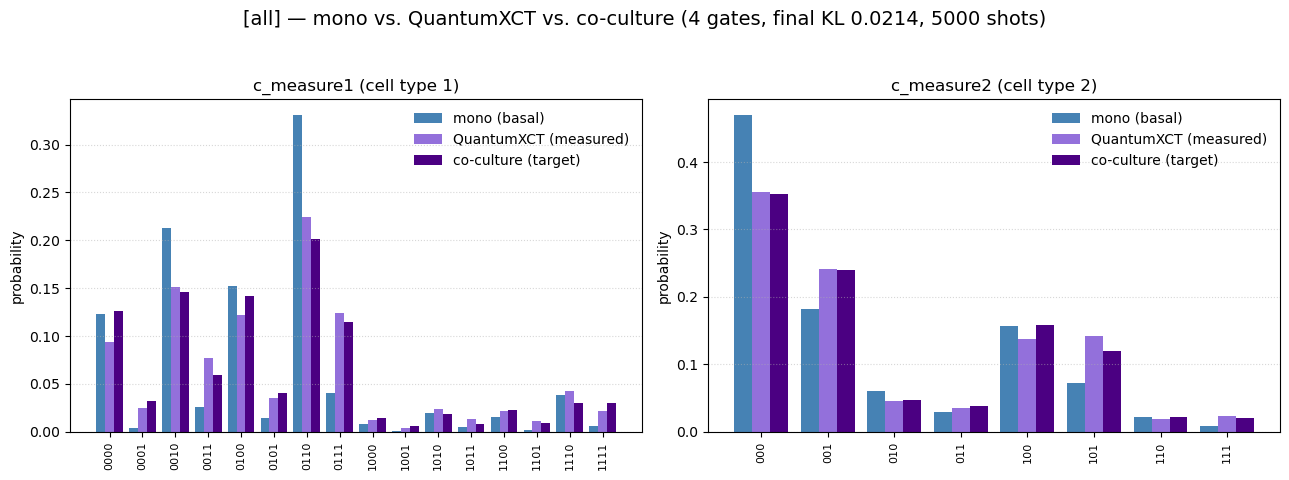


[all] optimized circuit (4 CRX gates):
              »
         q_0: »
              »
         q_1: »
              »
         q_2: »
              »
         q_3: »
              »
         q_4: »
              »
         q_5: »
              »
         q_6: »
              »
c_measure1: 4/»
              »
c_measure2: 3/»
              »
«              ┌──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐»
«         q_0: ┤0                                                                                                                                                 ├»
«              │                                                                                                                                                  │»
«         q_1: ┤1                                                                                                                                                

Counts for c_measure1: {'0101': 200, '0110': 1172, '0010': 708, '0001': 111, '0011': 390, '0000': 478, '0111': 667, '1110': 195, '0100': 593, '1000': 53, '1010': 107, '1101': 35, '1111': 112, '1011': 70, '1100': 94, '1001': 15}
Counts for c_measure2: {'001': 1148, '000': 1818, '100': 687, '101': 761, '010': 248, '011': 152, '111': 84, '110': 102}


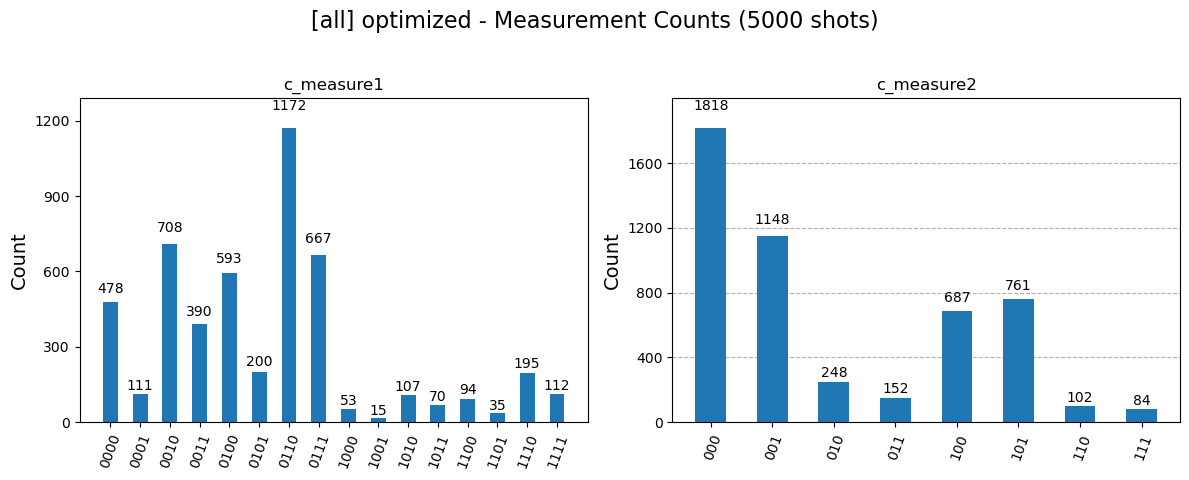

Histogram figure saved to results/ovarian_cocultured/all_measurement_histograms.png

--- Comprehensive Interaction Network Analysis & Summary ---



--- Gate Contribution Analysis (Ablation Study) ---
   Step         Interaction CRX Angle (rad) KL Divergence KL Change Cumulative KL Reduction Isolated KL Isolated Reduction % Contribution % Isolated Contribution % of Total Reduction CRX Angle (deg)
0     0  Baseline (0 gates)             nan        0.1892    0.0000                  0.0000         nan             0.0000          0.00%                   0.00%               -0.00%            nan°
1     1     STAT3 -> PDGFRB          1.5987        0.1571   -0.0320                 -0.0320      0.1571             0.0320         16.92%                  16.92%               19.08%          91.60°
2     2     PDGFRB -> PDGFB          1.7949        0.0356   -0.1215                 -0.1535      0.0827             0.1065         64.24%                  56.29%               72.44%         102.84°
3     3     PDGFB -> TGFBR2          1.5029        0.0268   -0.0089                 -0.1624      0.1837             0.0054          4.69%              

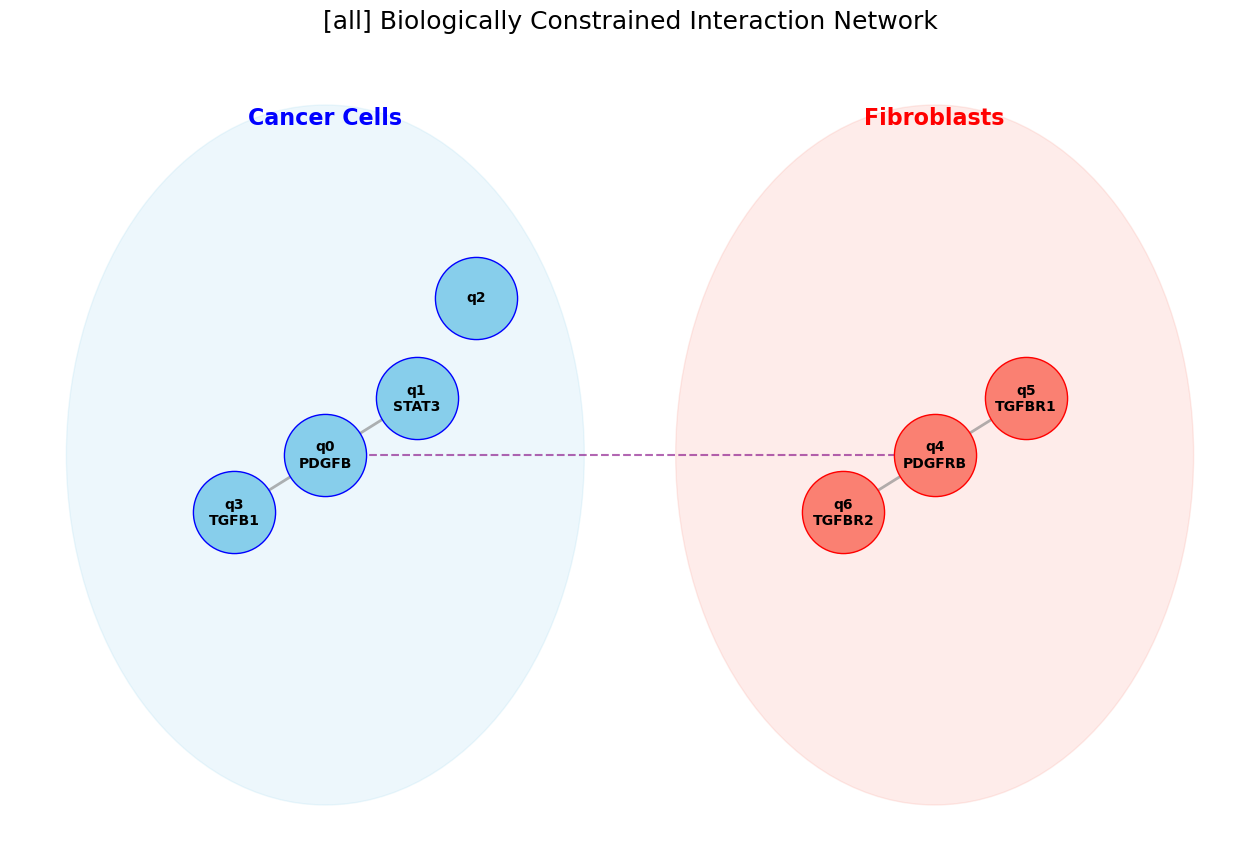

[GRN-only]  2 gates | baseline KL 0.1892 -> final KL 0.0538  (71.6% reduction)
Cumulative ablation reduction:
 Step        Interaction  CRX Angle (rad)  KL Divergence  KL Change  Cumulative KL Reduction  % of Baseline
    0 Baseline (0 gates)              NaN         0.1892     0.0000                   0.0000         0.0000
    1     STAT3 -> PDGFB           1.3782         0.1033    -0.0859                   0.0859        45.4009
    2     PDGFB -> STAT3           1.5551         0.0538    -0.0495                   0.1354        71.5579
Isolated / leave-one-out contribution:
          Gate  CRX Angle (rad)  Isolated KL  Isolated Reduction  LOO KL (without gate)  Marginal Contribution  % Marginal of Baseline
STAT3 -> PDGFB           1.3782       0.1033              0.0859                 0.1907                 0.1369                 72.3883
PDGFB -> STAT3           1.5551       0.1907             -0.0016                 0.1033                 0.0495                 26.1569


Saved histogram figure to results/ovarian_cocultured/intra_occupancy_3way.png


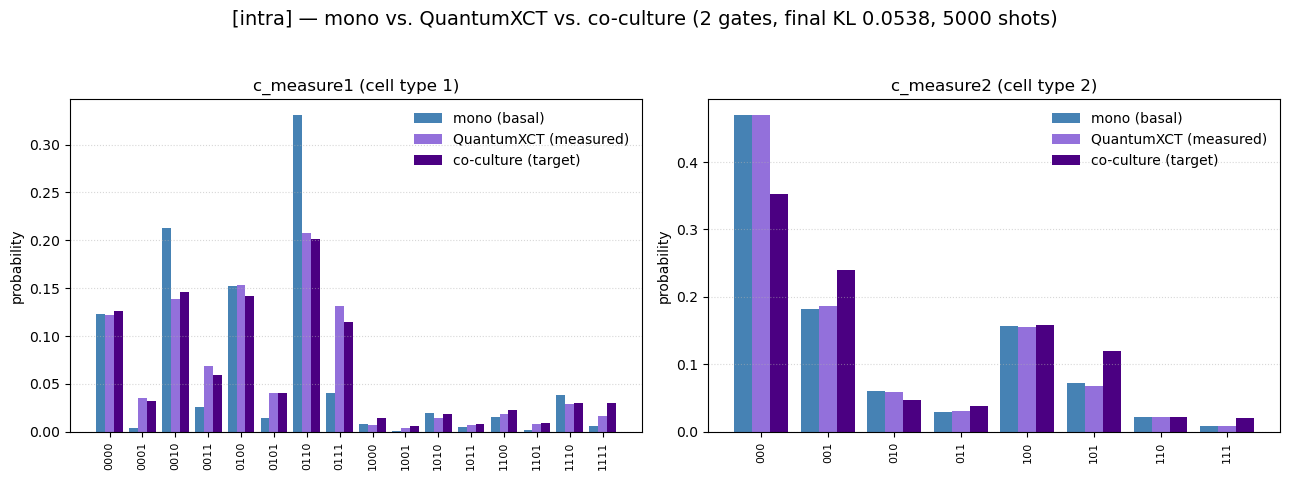


[intra] optimized circuit (2 CRX gates):
              »
         q_0: »
              »
         q_1: »
              »
         q_2: »
              »
         q_3: »
              »
         q_4: »
              »
         q_5: »
              »
         q_6: »
              »
c_measure1: 4/»
              »
c_measure2: 3/»
              »
«              ┌──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐»
«         q_0: ┤0                                                                                                                                                 ├»
«              │                                                                                                                                                  │»
«         q_1: ┤1                                                                                                                                              

Counts for c_measure1: {'0101': 220, '0100': 740, '0010': 643, '0110': 1104, '0001': 161, '0000': 612, '0011': 358, '0111': 686, '1110': 119, '1000': 37, '1010': 72, '1001': 23, '1111': 84, '1101': 26, '1011': 42, '1100': 73}
Counts for c_measure2: {'000': 2433, '001': 834, '100': 754, '010': 315, '101': 364, '011': 132, '110': 121, '111': 47}


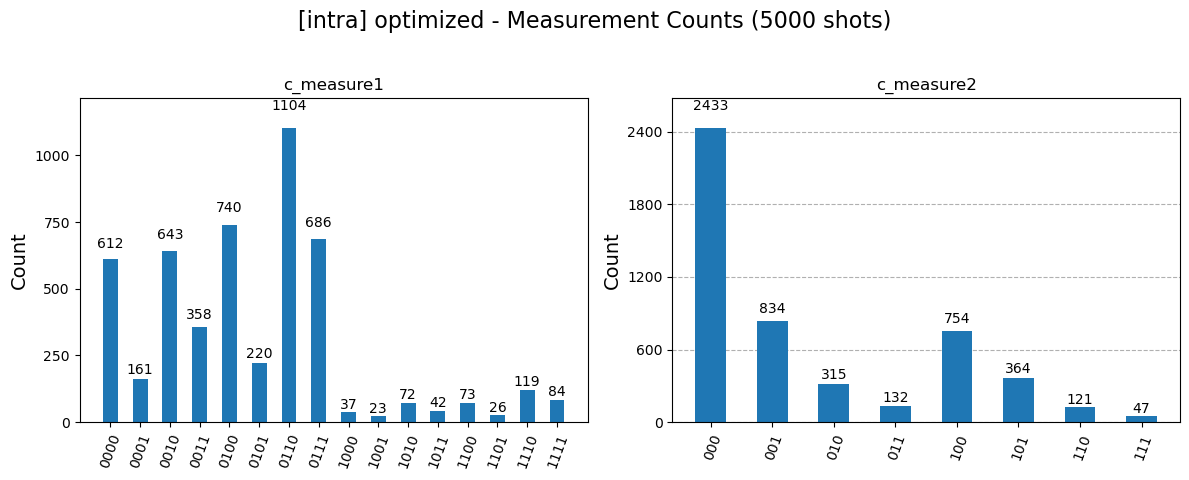

Histogram figure saved to results/ovarian_cocultured/intra_measurement_histograms.png

--- Comprehensive Interaction Network Analysis & Summary ---



--- Gate Contribution Analysis (Ablation Study) ---
   Step         Interaction CRX Angle (rad) KL Divergence KL Change Cumulative KL Reduction Isolated KL Isolated Reduction % Contribution % Isolated Contribution % of Total Reduction CRX Angle (deg)
0     0  Baseline (0 gates)             nan        0.1892    0.0000                  0.0000         nan             0.0000          0.00%                   0.00%               -0.00%            nan°
1     1      STAT3 -> PDGFB          1.3782        0.1033   -0.0859                 -0.0859      0.1033             0.0859         45.40%                  45.40%               63.45%          78.97°
2     2      PDGFB -> STAT3          1.5551        0.0538   -0.0495                 -0.1354      0.1907            -0.0016         26.16%                  -0.83%               36.55%          89.10°

--- Hub-based Interaction Summary ---
Gene 'PDGFB' interacts with: STAT3
Gene 'STAT3' interacts with: PDGFB

--- Full Set of Interacting Genes ---
['P

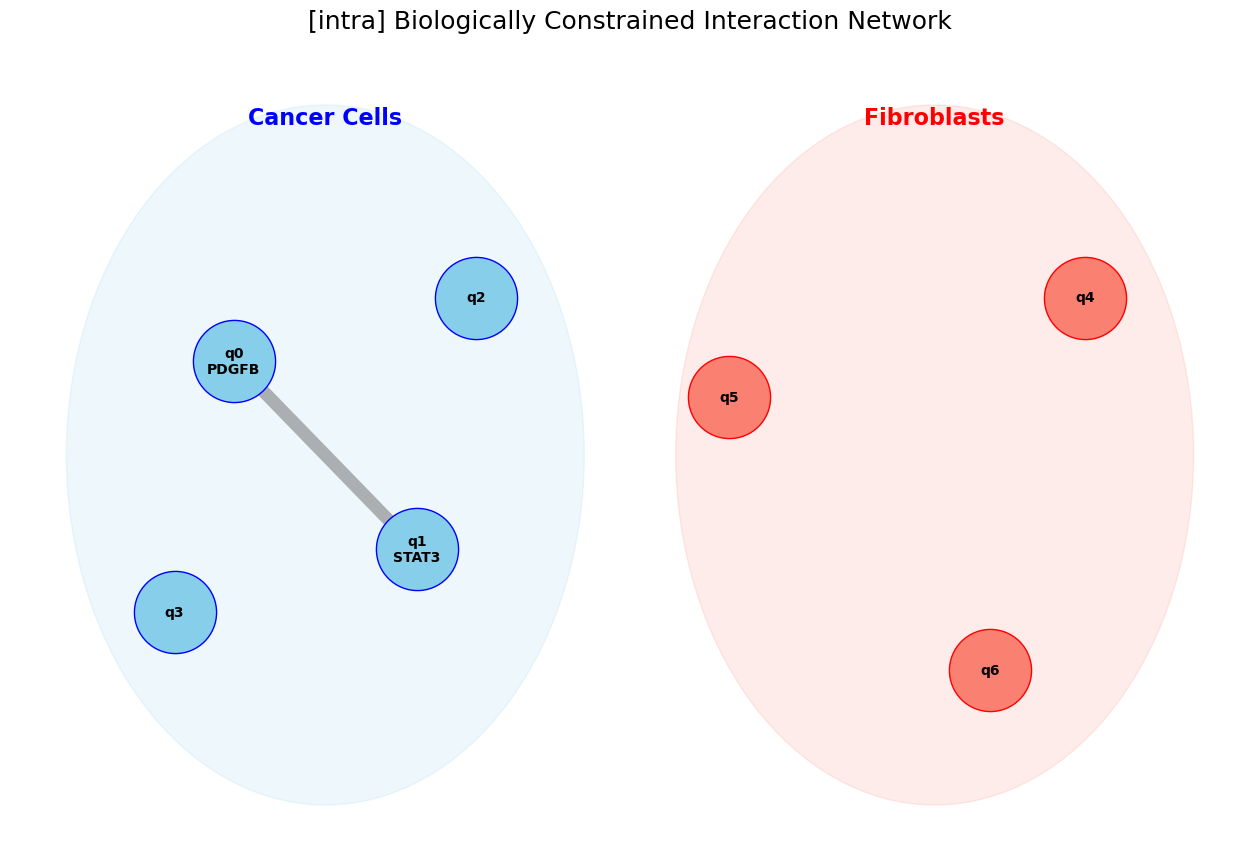

[LR-only]  3 gates | baseline KL 0.1892 -> final KL 0.0266  (85.9% reduction)
Cumulative ablation reduction:
 Step        Interaction  CRX Angle (rad)  KL Divergence  KL Change  Cumulative KL Reduction  % of Baseline
    0 Baseline (0 gates)              NaN         0.1892     0.0000                   0.0000         0.0000
    1    STAT3 -> PDGFRB           1.4271         0.1563    -0.0329                   0.0329        17.3746
    2    PDGFRB -> PDGFB           1.7781         0.0353    -0.1210                   0.1538        81.3309
    3    PDGFB -> TGFBR2           1.4693         0.0266    -0.0087                   0.1625        85.9219
Isolated / leave-one-out contribution:
           Gate  CRX Angle (rad)  Isolated KL  Isolated Reduction  LOO KL (without gate)  Marginal Contribution  % Marginal of Baseline
PDGFRB -> PDGFB           1.7781       0.0829              0.1062                 0.1508                 0.1242                 65.6380
STAT3 -> PDGFRB           1.4271       0

Saved histogram figure to results/ovarian_cocultured/inter_occupancy_3way.png


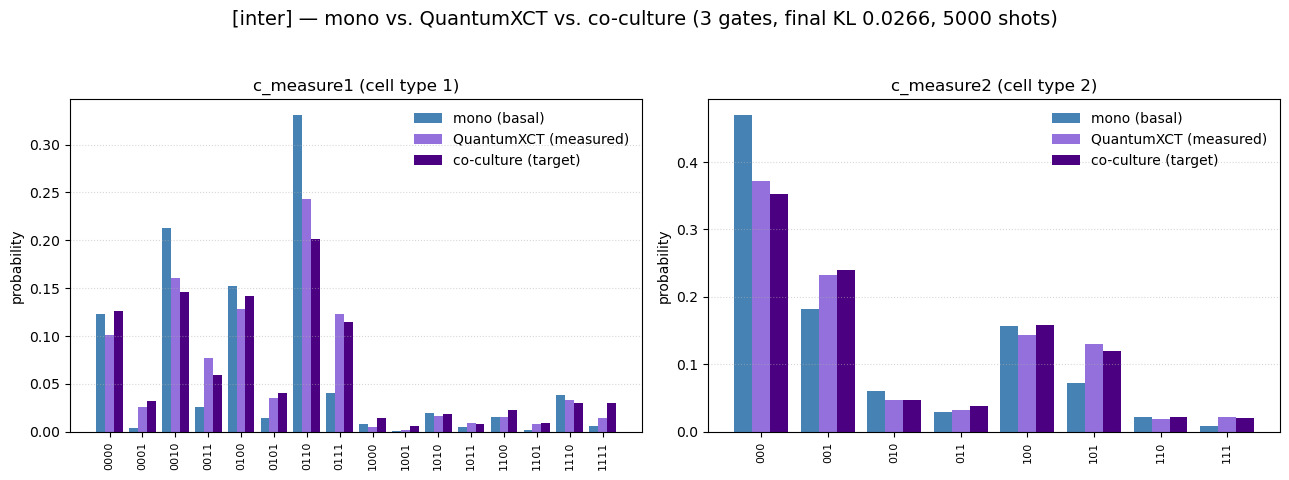


[inter] optimized circuit (3 CRX gates):
              »
         q_0: »
              »
         q_1: »
              »
         q_2: »
              »
         q_3: »
              »
         q_4: »
              »
         q_5: »
              »
         q_6: »
              »
c_measure1: 4/»
              »
c_measure2: 3/»
              »
«              ┌──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐»
«         q_0: ┤0                                                                                                                                                 ├»
«              │                                                                                                                                                  │»
«         q_1: ┤1                                                                                                                                              

Counts for c_measure1: {'0101': 209, '0110': 1286, '0010': 775, '0000': 499, '0011': 375, '0111': 647, '1110': 136, '0100': 616, '1000': 30, '1010': 79, '1101': 25, '1111': 80, '0001': 113, '1011': 51, '1100': 70, '1001': 9}
Counts for c_measure2: {'001': 1104, '000': 1900, '100': 695, '010': 260, '101': 695, '011': 136, '111': 91, '110': 119}


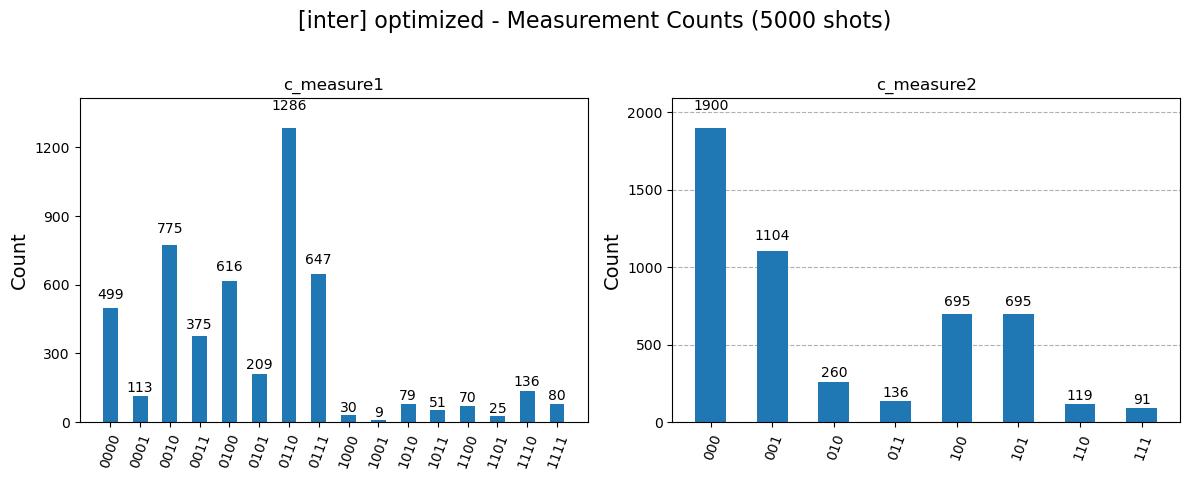

Histogram figure saved to results/ovarian_cocultured/inter_measurement_histograms.png

--- Comprehensive Interaction Network Analysis & Summary ---



--- Gate Contribution Analysis (Ablation Study) ---
   Step         Interaction CRX Angle (rad) KL Divergence KL Change Cumulative KL Reduction Isolated KL Isolated Reduction % Contribution % Isolated Contribution % of Total Reduction CRX Angle (deg)
0     0  Baseline (0 gates)             nan        0.1892    0.0000                  0.0000         nan             0.0000          0.00%                   0.00%               -0.00%            nan°
1     1     STAT3 -> PDGFRB          1.4271        0.1563   -0.0329                 -0.0329      0.1563             0.0329         17.37%                  17.37%               20.22%          81.77°
2     2     PDGFRB -> PDGFB          1.7781        0.0353   -0.1210                 -0.1538      0.0829             0.1062         63.96%                  56.15%               74.44%         101.88°
3     3     PDGFB -> TGFBR2          1.4693        0.0266   -0.0087                 -0.1625      0.1839             0.0052          4.59%              

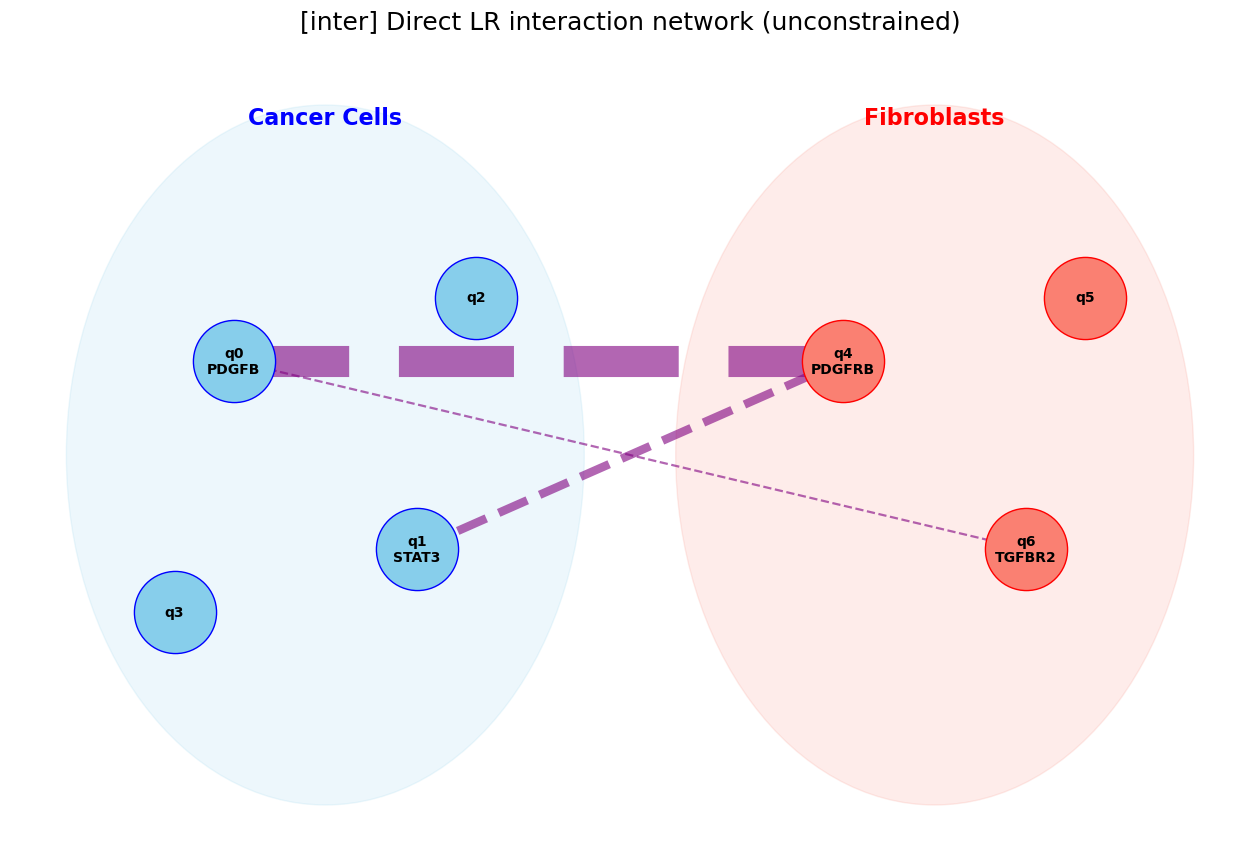

In [11]:
try:
    benchA
except NameError:
    benchA = compare_scopes(config, joint_counts_ct1_mo, joint_counts_ct2_mo,
                            joint_counts_ct1_co, joint_counts_ct2_co, gene_list=gl_all)

for scope, res in benchA['detail'].items():
    tag = {'all': 'GRN+LR', 'intra': 'GRN-only', 'inter': 'LR-only'}[scope]
    print('=' * 72)
    print(f"[{tag}]  {res['n_gates']} gates | baseline KL {res['baseline_kl']:.4f} -> "
          f"final KL {res['final_kl']:.4f}  ({res['pct_reduction']:.1f}% reduction)")
    print('Cumulative ablation reduction:')
    print(res['cumulative_ablation'].to_string(index=False))
    print('Isolated / leave-one-out contribution:')
    print(res['isolated_contribution'].to_string(index=False))
    res['cumulative_ablation'].to_csv(os.path.join(OUT_DIR, f'{scope}_cumulative_ablation.csv'), index=False)
    res['isolated_contribution'].to_csv(os.path.join(OUT_DIR, f'{scope}_isolated_contribution.csv'), index=False)
    plot_scope_report(res, gl_ct1=gl_ct1, gl_ct2=gl_ct2, valid_lr_pairs=valid_lr_pairs,
                      out_dir=OUT_DIR, scope=scope, ct1_name=ct1_name, ct2_name=ct2_name)

### Angle-initialization study (0 vs. π/2)
Optimize each scope's topology from 0 and π/2 and overlay the KL convergence curves.


[GRN+LR] angle-init comparison on 4-gate topology

--- Starting CRX Angle Optimization (4 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 48   Least value of F = 0.02040252675761013   Constraint violation = 0.0
The corresponding X is:
[1.54597884 1.89390917 1.29096661 1.09296879]
The constraint value is:
[-1.54597884 -1.89390917 -1.29096661 -1.09296879 -1.59561381 -1.24768348
 -1.85062604 -2.04862387]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['1.5460', '1.8939', '1.2910', '1.0930']
CRX Angle Optimization took: 3.49 seconds

--- Starting CRX Angle Optimization (4 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 42   Least value of F = 0.02141055389247892   Constraint violation = 0.0
The corresponding X is:
[1.59870538 1.79491567 1.50285773 1.48163593]
The constraint value is:
[-1.59870538 -1.79491567 -1.50285773 -1.48163593 -1.54288727 -1.34667699
 -1.63873492 -1.65995672]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['1.5987', '1.7949', '1.5029', '1.4816']
CRX Angle Optimization took: 2.97 seconds


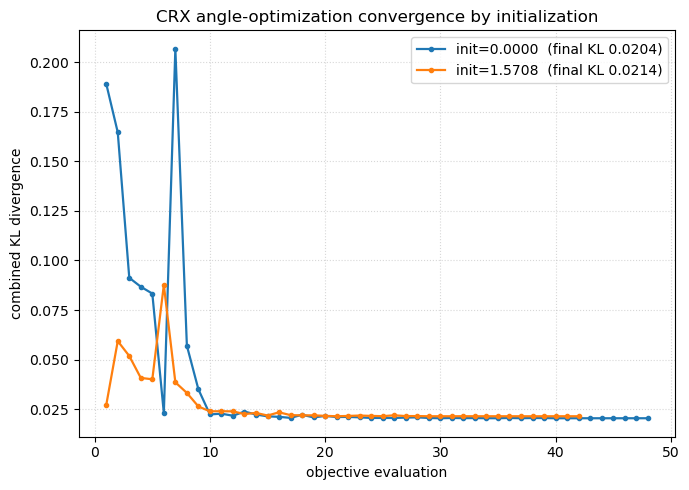

   init=0.0000 rad -> final KL 0.0204 (48 iters)
   init=1.5708 rad -> final KL 0.0214 (42 iters)
[GRN-only] angle-init comparison on 2-gate topology

--- Starting CRX Angle Optimization (2 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 39   Least value of F = 0.0536292011708607   Constraint violation = 0.0
The corresponding X is: [1.33258344 1.58418257]
The constraint value is:
[-1.33258344 -1.58418257 -1.80900921 -1.55741008]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['1.3326', '1.5842']
CRX Angle Optimization took: 2.73 seconds

--- Starting CRX Angle Optimization (2 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 29   Least value of F = 0.05379858412405947   Constraint violation = 0.0
The corresponding X is: [1.37822289 1.55512646]
The constraint value is:
[-1.37822289 -1.55512646 -1.76336977 -1.58646619]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['1.3782', '1.5551']
CRX Angle Optimization took: 2.03 seconds


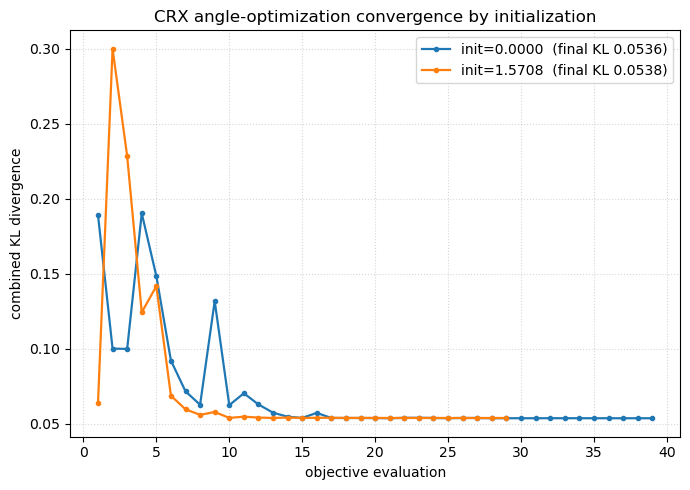

   init=0.0000 rad -> final KL 0.0536 (39 iters)
   init=1.5708 rad -> final KL 0.0538 (29 iters)
[LR-only] angle-init comparison on 3-gate topology

--- Starting CRX Angle Optimization (3 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 43   Least value of F = 0.02589758243937678   Constraint violation = 0.0
The corresponding X is:
[1.54040995 1.81684041 1.31555974]
The constraint value is:
[-1.54040995 -1.81684041 -1.31555974 -1.6011827  -1.32475224 -1.82603291]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['1.5404', '1.8168', '1.3156']
CRX Angle Optimization took: 3.14 seconds

--- Starting CRX Angle Optimization (3 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 32   Least value of F = 0.026628806095135283   Constraint violation = 0.0
The corresponding X is:
[1.42713763 1.77809498 1.46927236]
The constraint value is:
[-1.42713763 -1.77809498 -1.46927236 -1.71445503 -1.36349767 -1.67232029]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['1.4271', '1.7781', '1.4693']
CRX Angle Optimization took: 2.26 seconds


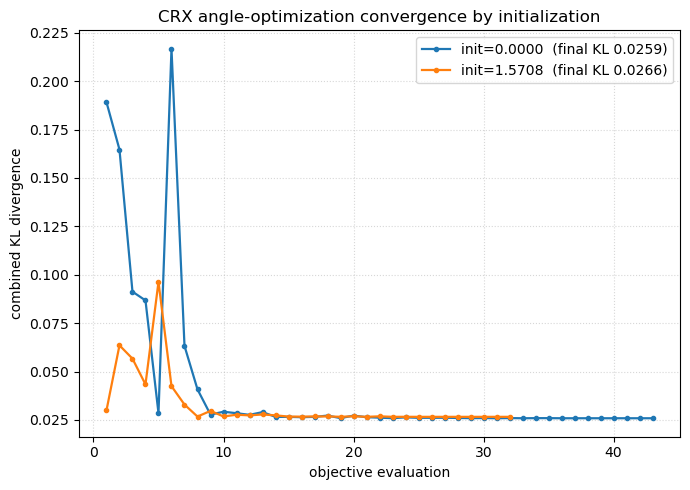

   init=0.0000 rad -> final KL 0.0259 (43 iters)
   init=1.5708 rad -> final KL 0.0266 (32 iters)


In [12]:
for scope, res in benchA['detail'].items():
    if res['n_gates'] == 0:
        continue
    tag = {'all': 'GRN+LR', 'intra': 'GRN-only', 'inter': 'LR-only'}[scope]
    print('=' * 72); print(f"[{tag}] angle-init comparison on {res['n_gates']}-gate topology")
    curves = compare_angle_initializations(
        res['circ1'], res['circ2'], res['target1'], res['target2'], res['topology'],
        inits=(0.0, np.pi / 2), nshots=res['nshots'], show_plot=True,
        filename=os.path.join(OUT_DIR, f'{scope}_angle_init_curves.png'))
    for iv, info in curves.items():
        print(f"   init={iv:.4f} rad -> final KL {info['final_kl']:.4f} ({len(info['history'])} iters)")

# Benchmark B — baseline methods (fair, budget-matched)
QuantumXCT best-effort sets the gate budget N; OT / Born / TN are shown at their minimum capacity. Same per-register KL to the co-culture target.


In [13]:
benchB = benchmark_budget_matched(
    config,
    joint_counts_ct1_mo, joint_counts_ct2_mo,
    joint_counts_ct1_co, joint_counts_ct2_co,
    gene_list=gl_all, qx_best_effort=True,
    born_bond_dims=(1, 2), tn_bond_dims=(1, 2),   # D=1 minimal floor + D=2 fair entangled capacity
)
print('QuantumXCT gate budget N =', benchB['quantumxct_gates'], '| topology:', benchB['topology'])

# Framing: keep the interpretation next to the numbers (see qxct.baselines.BENCHMARK_B_CAPTION)
import textwrap
print('\n' + textwrap.fill(benchB['caption'], 100) + '\n')
with open(os.path.join(OUT_DIR, 'benchmark_B_caption.txt'), 'w', encoding='utf-8') as _fh:
    _fh.write(benchB['caption'])

benchB['summary'].to_csv(os.path.join(OUT_DIR, 'baseline_methods_budget_matched.csv'), index=False)
benchB['summary']


--- CNOT Analysis (pos) ---
Max Signal: 0.0213
Candidates Found: 42 / 42
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 42


Initial KL divergence (baseline): 0.189151

--- Starting Epoch 1/42 (Addition) with CNOT: (1, 4) (KL: 0.156834) ---


    --> Found a better KL on this path: 0.038866 at depth 2 with added CNOT (4, 0)


    --> Found a better KL on this path: 0.029930 at depth 3 with added CNOT (0, 6)


    --> Found a better KL on this path: 0.027033 at depth 4 with added CNOT (5, 3)


...

    --> Found a better KL on this path: 0.034595 at depth 7 with added CNOT (5, 4)


  Epoch 42 best KL Sum: 0.034595

Final Result: Best sequence found has 5 CNOTs (KL: 0.018289).

Total search took: 360.19 seconds.

--- Starting CRX Angle Optimization (5 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 65   Least value of F = 0.00675262119362571   Constraint violation = 0.0
The corresponding X is:
[1.34988037 1.57256307 1.62706993 1.54354291 1.47176487]
The constraint value is:
[-1.34988037 -1.57256307 -1.62706993 -1.54354291 -1.47176487 -1.79171228
 -1.56902958 -1.51452273 -1.59804974 -1.66982778]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['1.3499', '1.5726', '1.6271', '1.5435', '1.4718']
CRX Angle Optimization took: 4.64 seconds


QuantumXCT gate budget N = 5 | topology: [(1, 0), (0, 1), (2, 4), (0, 6), (5, 3)]

Benchmark B is a KL-at-matched-budget comparison. Optimal Transport and the Born machine are
descriptive lower bounds on achievable KL, not mechanistic competitors: they map distributions but
yield no edges and no directions (see the 'interpretable network' column). QuantumXCT's claim is not
'lowest KL' but reaching comparable KL while ALSO returning a directed, interpretable gene network.
Note the two OT views reported together: the full (uncapped) solve in compare_baselines() is OT's
best case, while benchmark_budget_matched() caps OT to the top-k couplings at QuantumXCT's gate
budget.



,Method,setting,KL (c1+c2),# params,within budget?,conditioned on basal,interpretable network
0,QuantumXCT,5 gates,0.0068,5,yes,yes,yes
1,Optimal Transport,top-5/register,0.1939,10,no,yes,no
2,TN transform,bond_dim=1,0.0007,28,no,yes,no
3,Born machine,bond_dim=1,0.0194,14,no,no,no


# L1 vs L2 encoding comparison
Same pipeline under both encodings. **L2** (paper, Eqs 1–2): amplitude = count/‖count‖₂, prob ∝ count² (emphasizes common states). **L1** (default): amplitude = √(count/Σcount), prob = frequency (frequency-preserving).
Real data has no ground-truth network, so `include_recovery=False` — we report own-encoding KL, the common-reference KL vs true co-culture frequency, gates and runtime.



--- CNOT Analysis (pos) ---
Max Signal: 0.0213
Candidates Found: 42 / 42
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 42
Initial KL divergence (baseline): 0.189151

--- Starting Epoch 1/42 (Addition) with CNOT: (1, 4) (KL: 0.156834) ---


    --> Found a better KL on this path: 0.038866 at depth 2 with added CNOT (4, 0)


    --> Found a better KL on this path: 0.029930 at depth 3 with added CNOT (0, 6)


    --> Found a better KL on this path: 0.027033 at depth 4 with added CNOT (5, 3)


  Epoch 1 best KL Sum: 0.027033
  --> Epoch 1 found a new overall best KL Sum: 0.027033

--- Starting Greedy CNOT Removal Search on Best Found Sequence ---
  Starting removal search with 4 CNOTs (KL Sum: 0.027033)


...

    --> Found a better KL on this path: 0.052967 at depth 10 with added CNOT (3, 4)


    --> Found a better KL on this path: 0.052868 at depth 11 with added CNOT (3, 0)


  Epoch 35 best KL Sum: 0.052868

--- Starting Epoch 36/38 (Addition) with CNOT: (2, 6) (KL: 0.422360) ---
  Skipping epoch: Single CNOT KL (0.422360) does not improve over baseline (0.320914).

--- Starting Epoch 37/38 (Addition) with CNOT: (0, 2) (KL: 0.322840) ---
  Skipping epoch: Single CNOT KL (0.322840) does not improve over baseline (0.320914).



--- Starting Epoch 38/38 (Addition) with CNOT: (1, 2) (KL: 0.357547) ---
  Skipping epoch: Single CNOT KL (0.357547) does not improve over baseline (0.320914).

Final Result: Best sequence found has 5 CNOTs (KL: 0.041882).

Total search took: 381.07 seconds.

--- Starting CRX Angle Optimization (5 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 59   Least value of F = 0.025851584598730167   Constraint violation = 0.0
The corresponding X is:
[1.51832736 1.36872069 1.85726012 1.69336891 1.62240456]
The constraint value is:
[-1.51832736 -1.36872069 -1.85726012 -1.69336891 -1.62240456 -1.62326529
 -1.77287196 -1.28433254 -1.44822375 -1.51918809]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['1.5183', '1.3687', '1.8573', '1.6934', '1.6224']
CRX Angle Optimization took: 4.18 seconds


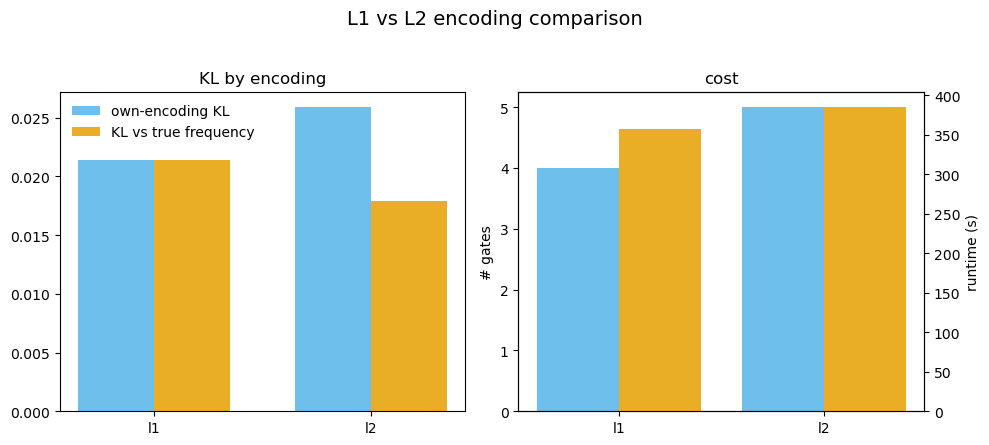

,norm,scope,n_gates,own_baseline_kl,own_final_kl,own_pct_reduction,ref_kl_vs_frequency,runtime_s
0,l1,all,4,0.1892,0.0214,88.6800,0.0214,358.0300
1,l2,all,5,0.3209,0.0259,91.9400,0.0179,385.2500


In [14]:
norm_cmp = compare_norms(
    config,
    joint_counts_ct1_mo, joint_counts_ct2_mo,
    joint_counts_ct1_co, joint_counts_ct2_co,
    gene_list=gl_all, norms=('l1', 'l2'), scope='all',
    include_recovery=False,
    out_dir=os.path.join(OUT_DIR, 'norm_comparison'), show=True,
)
norm_cmp['summary']

# Search-algorithm comparison (each saved to its own folder)
Runs every `SearchConfig.algorithm` on the same co-culture data (scope = GRN+LR) and tabulates gates / final KL / reduction. **Each algorithm's full output is saved to its own subfolder** `results/ovarian_cocultured/algorithm_comparison/<algorithm>/` (saved run + occupancy / circuit / measurement / relay figures + ablation), so nothing overlaps and results are easy to pull per algorithm. `vqe_hybrid` is the heaviest (one qubit per candidate CNOT); it is wrapped so a failure won't stop the others.


--- CNOT Analysis (pos) ---
Max Signal: 0.0213
Candidates Found: 42 / 42
------------------------------


--- Starting Multi-Epoch Refined Search ---

--- Using provided CNOT candidate list for the search. ---
Number of candidates to be searched: 42
Initial KL divergence (baseline): 0.189151

--- Starting Epoch 1/42 (Addition) with CNOT: (1, 4) (KL: 0.156834) ---


    --> Found a better KL on this path: 0.038866 at depth 2 with added CNOT (4, 0)


    --> Found a better KL on this path: 0.029930 at depth 3 with added CNOT (0, 6)


    --> Found a better KL on this path: 0.027033 at depth 4 with added CNOT (5, 3)


  Epoch 1 best KL Sum: 0.027033
  --> Epoch 1 found a new overall best KL Sum: 0.027033

--- Starting Greedy CNOT Removal Search on Best Found Sequence ---
  Starting removal search with 4 CNOTs (KL Sum: 0.027033)


...

    --> Found a better KL on this path: 0.034595 at depth 7 with added CNOT (5, 4)


  Epoch 42 best KL Sum: 0.034595

Final Result: Best sequence found has 4 CNOTs (KL: 0.027033).

Total search took: 355.51 seconds.

--- Starting CRX Angle Optimization (4 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 42   Least value of F = 0.02141055389247892   Constraint violation = 0.0
The corresponding X is:
[1.59870538 1.79491567 1.50285773 1.48163593]
The constraint value is:
[-1.59870538 -1.79491567 -1.50285773 -1.48163593 -1.54288727 -1.34667699
 -1.63873492 -1.65995672]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['1.5987', '1.7949', '1.5029', '1.4816']
CRX Angle Optimization took: 2.93 seconds

--- Comprehensive Interaction Network Analysis & Summary ---



--- Gate Contribution Analysis (Ablation Study) ---
   Step         Interaction CRX Angle (rad) KL Divergence KL Change Cumulative KL Reduction Isolated KL Isolated Reduction % Contribution % Isolated Contribution % of Total Reduction CRX Angle (deg)
0     0  Baseline (0 gates)             nan        0.1892    0.0000                  0.0000         nan             0.0000          0.00%                   0.00%               -0.00%            nan°
1     1     STAT3 -> PDGFRB          1.5987        0.1571   -0.0320                 -0.0320      0.1571             0.0320         16.92%                  16.92%               19.08%          91.60°
2     2     PDGFRB -> PDGFB          1.7949        0.0356   -0.1215                 -0.1535      0.0827             0.1065         64.24%                  56.29%               72.44%         102.84°
3     3     PDGFB -> TGFBR2          1.5029        0.0268   -0.0089                 -0.1624      0.1837             0.0054          4.69%              

Saved histogram figure to results/ovarian_cocultured/algorithm_comparison/multi_epoch/all_occupancy_3way.png


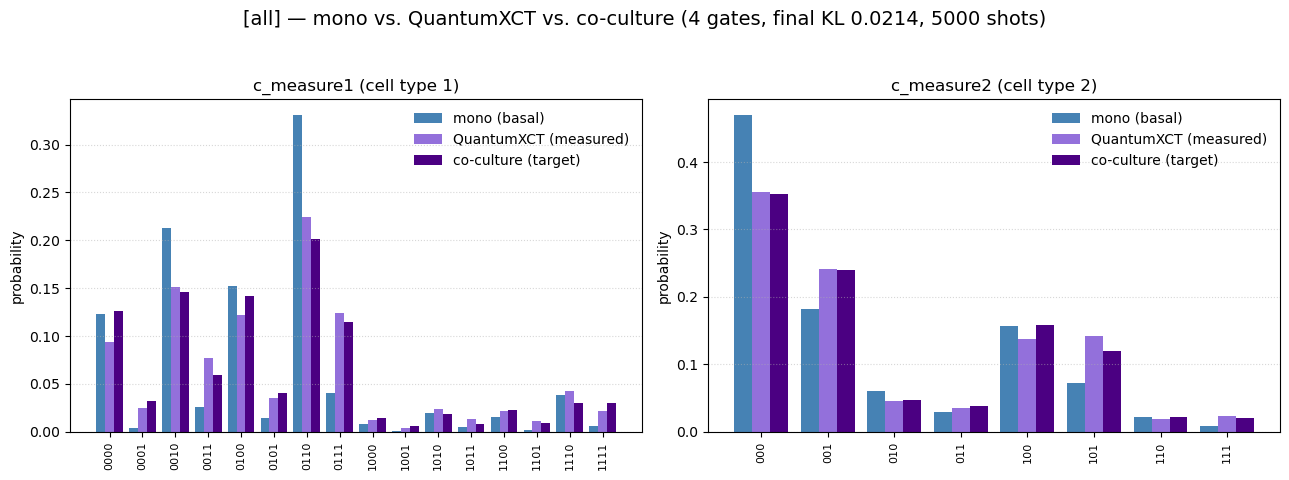


[all] optimized circuit (4 CRX gates):
              »
         q_0: »
              »
         q_1: »
              »
         q_2: »
              »
         q_3: »
              »
         q_4: »
              »
         q_5: »
              »
         q_6: »
              »
c_measure1: 4/»
              »
c_measure2: 3/»
              »
«              ┌──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐»
«         q_0: ┤0                                                                                                                                                 ├»
«              │                                                                                                                                                  │»
«         q_1: ┤1                                                                                                                                                

Counts for c_measure1: {'0101': 200, '0110': 1172, '0010': 708, '0001': 111, '0011': 390, '0000': 478, '0111': 667, '1110': 195, '0100': 593, '1000': 53, '1010': 107, '1101': 35, '1111': 112, '1011': 70, '1100': 94, '1001': 15}
Counts for c_measure2: {'001': 1148, '000': 1818, '100': 687, '101': 761, '010': 248, '011': 152, '111': 84, '110': 102}


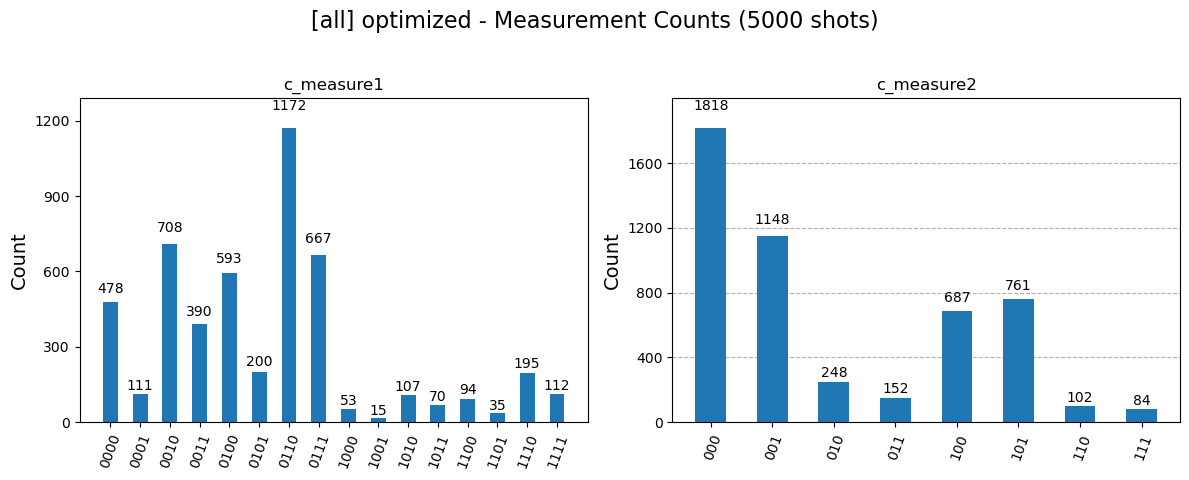

Histogram figure saved to results/ovarian_cocultured/algorithm_comparison/multi_epoch/all_measurement_histograms.png

--- Comprehensive Interaction Network Analysis & Summary ---



--- Gate Contribution Analysis (Ablation Study) ---
   Step         Interaction CRX Angle (rad) KL Divergence KL Change Cumulative KL Reduction Isolated KL Isolated Reduction % Contribution % Isolated Contribution % of Total Reduction CRX Angle (deg)
0     0  Baseline (0 gates)             nan        0.1892    0.0000                  0.0000         nan             0.0000          0.00%                   0.00%               -0.00%            nan°
1     1     STAT3 -> PDGFRB          1.5987        0.1571   -0.0320                 -0.0320      0.1571             0.0320         16.92%                  16.92%               19.08%          91.60°
2     2     PDGFRB -> PDGFB          1.7949        0.0356   -0.1215                 -0.1535      0.0827             0.1065         64.24%                  56.29%               72.44%         102.84°
3     3     PDGFB -> TGFBR2          1.5029        0.0268   -0.0089                 -0.1624      0.1837             0.0054          4.69%              

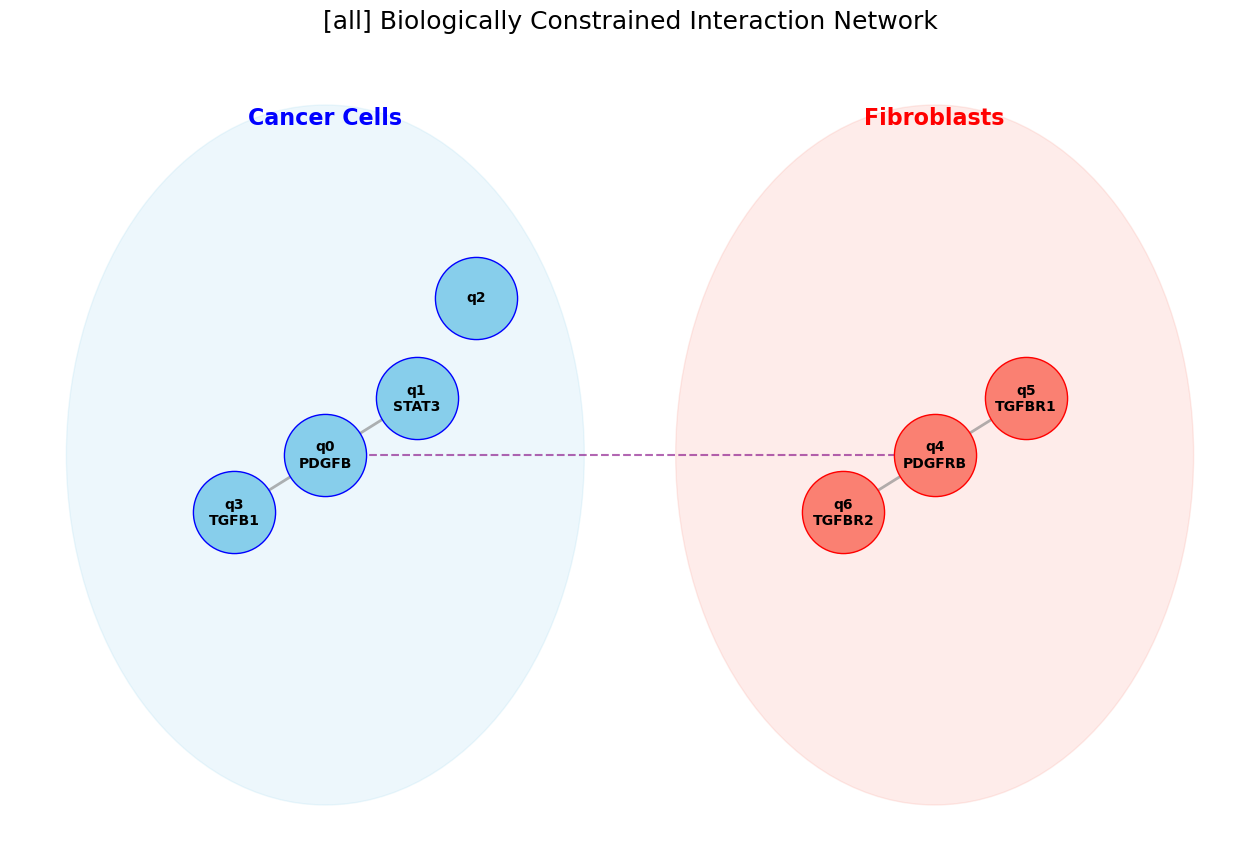

[multi_epoch] 4 gates, final KL 0.0214 -> saved to results/ovarian_cocultured/algorithm_comparison/multi_epoch

--- CNOT Analysis (pos) ---
Max Signal: 0.0213
Candidates Found: 42 / 42
------------------------------


--- Starting Iterative Pairwise Search ---


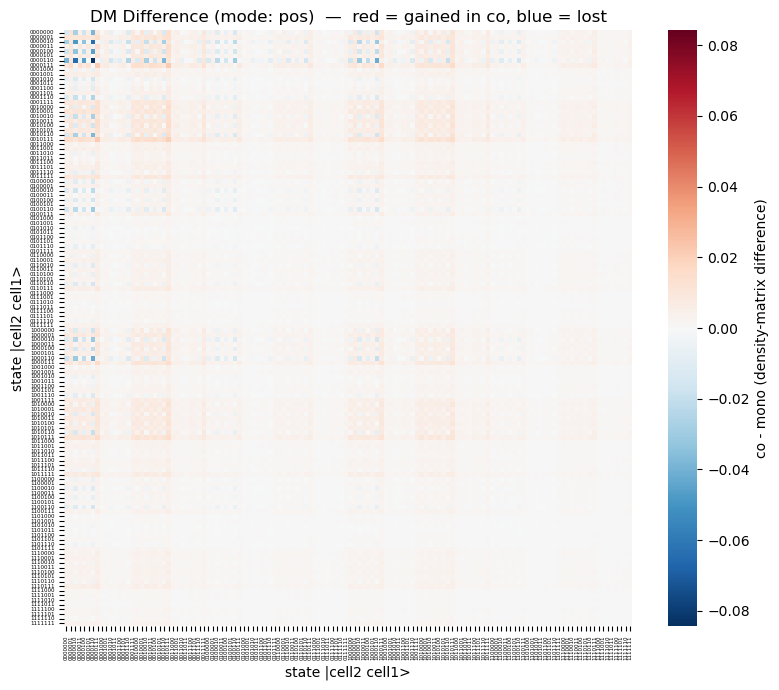


--- CNOT Analysis (pos) ---
Max Signal: 0.0213
Candidates Found: 42 / 42
------------------------------

Number of initial CNOT candidates: 42
Initial KL-divergence: 0.189151

  - Starting Efficiency-Optimized Search -

--- Iteration 1 | Current KL: 0.189151 ---


   - Single Insertion Phase: Added (4, 0) at index 0. New KL: 0.091315
  [Phase 1] Added Single: (4, 0) | New KL: 0.091315


  [Phase 2] Added Pair: ((6, 0), (0, 4)) | New KL: 0.050265



--- Iteration 2 | Current KL: 0.050265 ---


  [Phase 2] Added Pair: ((3, 6), (5, 1)) | New KL: 0.037597



--- Iteration 3 | Current KL: 0.037597 ---


  - No improvements in any phase. Search Terminated.

--- Total Search Time: 342.63s ---

--- Pairwise Addition Result ---
Best sequence after addition: [(4, 0), (6, 0), (0, 4), (3, 6), (5, 1)]
KL sum after addition: 0.037597

Total search time: 343.25 seconds.

--- Starting CRX Angle Optimization (5 CRX gates) ---


Return from COBYLA because the trust region radius reaches its lower bound.
Number of function values = 50   Least value of F = 0.030178475687741756   Constraint violation = 0.0
The corresponding X is:
[1.3656648  1.41806845 1.40495492 2.57573616 2.69289434]
The constraint value is:
[-1.3656648  -1.41806845 -1.40495492 -2.57573616 -2.69289434 -1.77592785
 -1.72352421 -1.73663773 -0.56585649 -0.44869831]


Optimization Results:
  Success: True
  Message: Return from COBYLA because the trust region radius reaches its lower bound.
  Optimized Angles: ['1.3657', '1.4181', '1.4050', '2.5757', '2.6929']
CRX Angle Optimization took: 3.47 seconds

--- Comprehensive Interaction Network Analysis & Summary ---



--- Gate Contribution Analysis (Ablation Study) ---
   Step         Interaction CRX Angle (rad) KL Divergence KL Change Cumulative KL Reduction Isolated KL Isolated Reduction % Contribution % Isolated Contribution % of Total Reduction CRX Angle (deg)
0     0  Baseline (0 gates)             nan        0.1892    0.0000                  0.0000         nan             0.0000          0.00%                   0.00%               -0.00%            nan°
1     1     PDGFRB -> PDGFB          1.3657        0.1054   -0.0837                 -0.0837      0.1054             0.0837         44.27%                  44.27%               52.68%          78.25°
2     2     TGFBR2 -> PDGFB          1.4181        0.0770   -0.0284                 -0.1121      0.1031             0.0861         15.00%                  45.51%               17.84%          81.25°
3     3     PDGFB -> PDGFRB          1.4050        0.0473   -0.0297                 -0.1418      0.1805             0.0087         15.70%              

Saved histogram figure to results/ovarian_cocultured/algorithm_comparison/iterative_n_wise/all_occupancy_3way.png


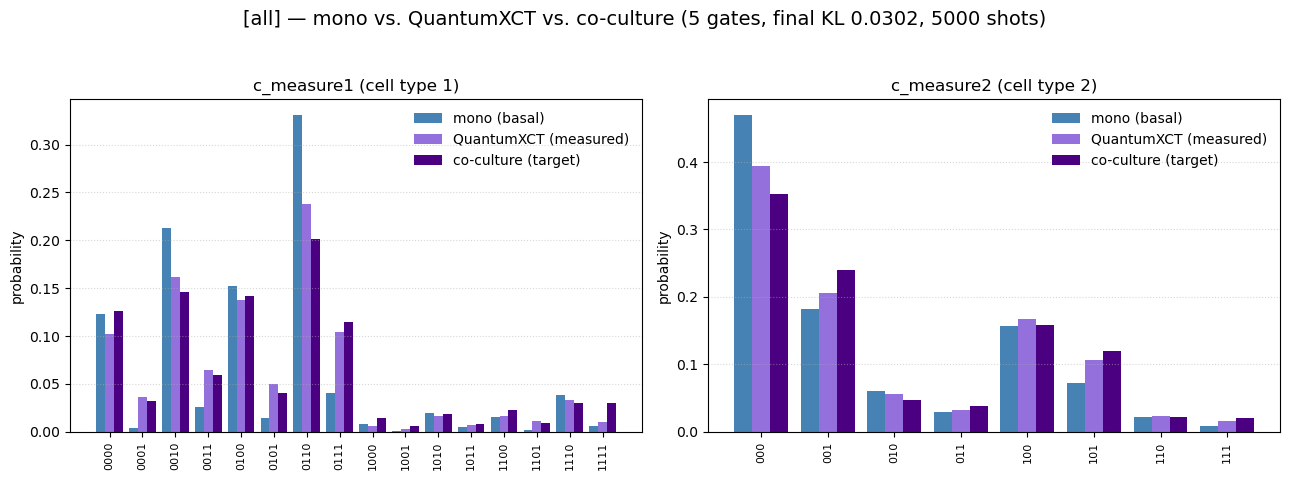


[all] optimized circuit (5 CRX gates):
              »
         q_0: »
              »
         q_1: »
              »
         q_2: »
              »
         q_3: »
              »
         q_4: »
              »
         q_5: »
              »
         q_6: »
              »
c_measure1: 4/»
              »
c_measure2: 3/»
              »
«              ┌──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────┐»
«         q_0: ┤0                                                                                                                                                 ├»
«              │                                                                                                                                                  │»
«         q_1: ┤1                                                                                                                                                

Counts for c_measure1: {'0101': 287, '0110': 1273, '0010': 776, '0000': 512, '0100': 655, '0011': 319, '0111': 539, '1110': 129, '1000': 30, '1010': 74, '1101': 34, '1111': 69, '0001': 165, '1011': 41, '1100': 76, '1001': 21}
Counts for c_measure2: {'001': 983, '000': 2035, '100': 809, '101': 562, '010': 268, '011': 156, '110': 124, '111': 63}


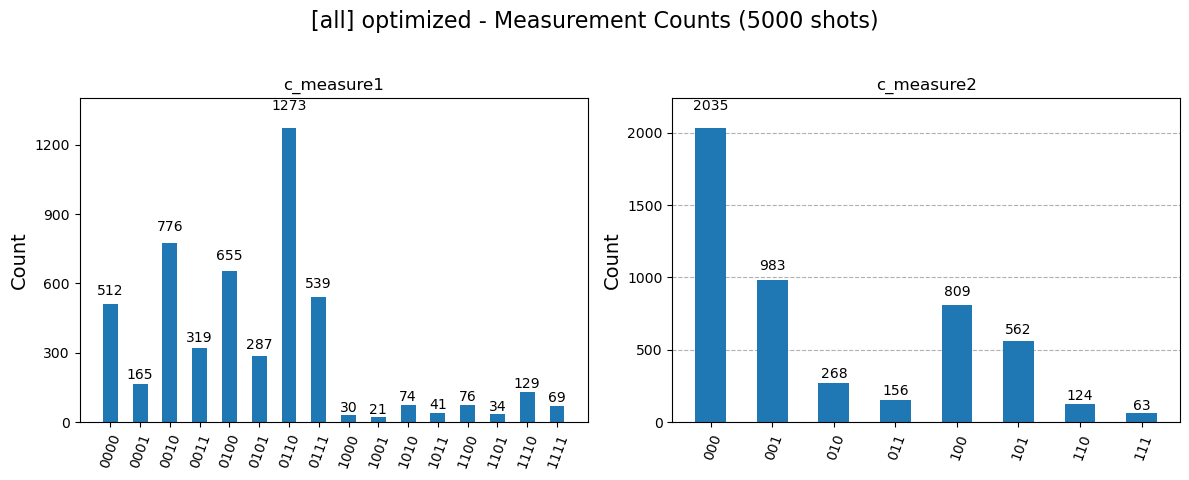

Histogram figure saved to results/ovarian_cocultured/algorithm_comparison/iterative_n_wise/all_measurement_histograms.png

--- Comprehensive Interaction Network Analysis & Summary ---



--- Gate Contribution Analysis (Ablation Study) ---
   Step         Interaction CRX Angle (rad) KL Divergence KL Change Cumulative KL Reduction Isolated KL Isolated Reduction % Contribution % Isolated Contribution % of Total Reduction CRX Angle (deg)
0     0  Baseline (0 gates)             nan        0.1892    0.0000                  0.0000         nan             0.0000          0.00%                   0.00%               -0.00%            nan°
1     1     PDGFRB -> PDGFB          1.3657        0.1054   -0.0837                 -0.0837      0.1054             0.0837         44.27%                  44.27%               52.68%          78.25°
2     2     TGFBR2 -> PDGFB          1.4181        0.0770   -0.0284                 -0.1121      0.1031             0.0861         15.00%                  45.51%               17.84%          81.25°
3     3     PDGFB -> PDGFRB          1.4050        0.0473   -0.0297                 -0.1418      0.1805             0.0087         15.70%              

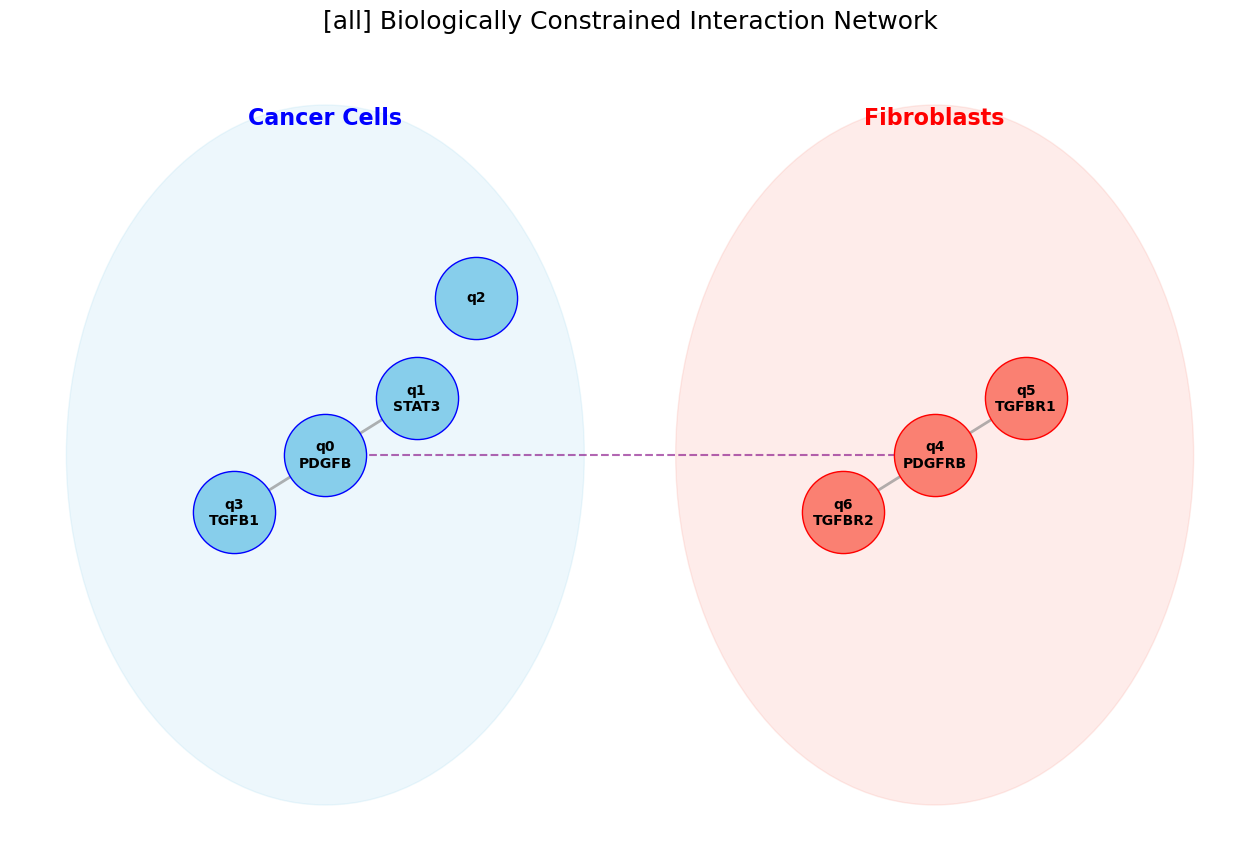

[iterative_n_wise] 5 gates, final KL 0.0302 -> saved to results/ovarian_cocultured/algorithm_comparison/iterative_n_wise

--- CNOT Analysis (pos) ---
Max Signal: 0.0213
Candidates Found: 42 / 42
------------------------------


--- Identifying Potential CNOT Linkers from Density Matrix Difference ---


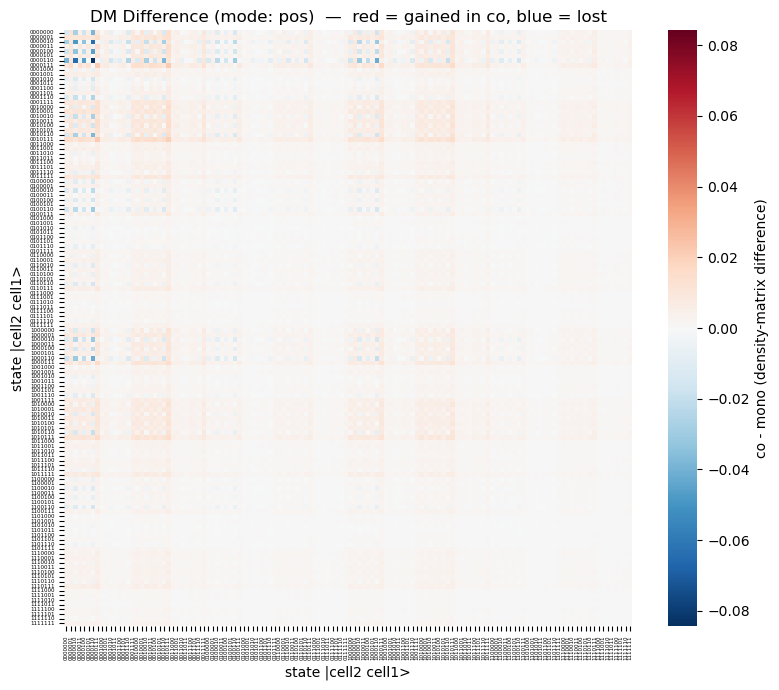


--- CNOT Analysis (pos) ---
Max Signal: 0.0213
Candidates Found: 42 / 42
------------------------------

Initial KL Divergence (no CNOTs): 0.189151

--- Building KL Divergence Matrix (42x42) ---
Calculating KL for single CNOTs (diagonal elements)...


Calculating KL for CNOT pairs (off-diagonal elements)...


Simulation failed and returned the following error message:
ERROR:  [Experiment 0] Insufficient memory to run circuit EfficientSU2-1628893 using the statevector simulator. Required memory: 67108864M, max memory: 127489M


Total CNOT pairs tested: 1722
--- KL Divergence Matrix Built ---
Starting optimization with method: COBYLA
[vqe_hybrid] FAILED: QiskitError: 'ERROR:  [Experiment 0] Insufficient memory to run circuit EfficientSU2-1628893 using the statevector simulator. Required memory: 67108864M, max memory: 127489M ,  ERROR: Insufficient memory to run circuit EfficientSU2-1628893 using the statevector simulator. Required memory: 67108864M, max memory: 127489M'


,algorithm,# gates,final KL,baseline KL,KL reduction,% reduction
0,multi_epoch,4.0000,0.0214,0.1892,0.1677,88.7000
1,iterative_n_wise,5.0000,0.0302,0.1892,0.1590,84.0000
2,vqe_hybrid,NaN,NaN,NaN,NaN,NaN


In [15]:
import dataclasses
from qxct.analysis import baseline_kl

ALGORITHMS = ['multi_epoch', 'iterative_n_wise', 'vqe_hybrid']
algo_root = os.path.join(OUT_DIR, 'algorithm_comparison')
os.makedirs(algo_root, exist_ok=True)
algo_runs, algo_rows = {}, []
for algo in ALGORITHMS:
    sub = os.path.join(algo_root, algo)
    os.makedirs(sub, exist_ok=True)
    try:
        s = dataclasses.replace(config.search, algorithm=algo, candidate_scope='all')
        cfg_a = dataclasses.replace(config, search=s)
        qx_a = QuantumXct(cfg_a, gene_list=gl_all)
        qx_a.encode(joint_counts_ct1_mo, joint_counts_ct2_mo, joint_counts_ct1_co, joint_counts_ct2_co)
        res_a = qx_a.run()
        base = baseline_kl(qx_a.circ1, qx_a.circ2, qx_a.target1, qx_a.target2, config.backend.shots, None)
        # save this algorithm's full outputs into its own folder
        qx_a.save(os.path.join(sub, 'run'), metadata={'algorithm': algo})
        if res_a.contribution_df is not None:
            res_a.contribution_df.to_csv(os.path.join(sub, 'ablation.csv'), index=False)
        qx_a.plot_report(gl_ct1=gl_ct1, gl_ct2=gl_ct2, valid_lr_pairs=valid_lr_pairs,
                         out_dir=sub, ct1_name=ct1_name, ct2_name=ct2_name)
        algo_rows.append({'algorithm': algo, '# gates': len(res_a.topology),
                          'final KL': round(res_a.kl_sum, 4), 'baseline KL': round(base, 4),
                          'KL reduction': round(base - res_a.kl_sum, 4),
                          '% reduction': round((base - res_a.kl_sum) / base * 100 if base > 1e-12 else 0.0, 1)})
        algo_runs[algo] = qx_a
        print(f'[{algo}] {len(res_a.topology)} gates, final KL {res_a.kl_sum:.4f} -> saved to {sub}')
    except Exception as e:
        print(f'[{algo}] FAILED: {type(e).__name__}: {e}')
        algo_rows.append({'algorithm': algo, '# gates': None, 'final KL': None,
                          'baseline KL': None, 'KL reduction': None, '% reduction': None})
algo_df = pd.DataFrame(algo_rows)
algo_df.to_csv(os.path.join(algo_root, 'algorithm_comparison.csv'), index=False)
algo_df

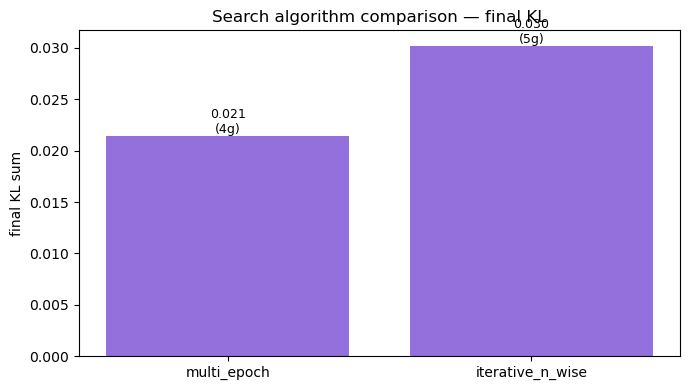

In [16]:
import matplotlib.pyplot as plt
d = algo_df.dropna(subset=['final KL'])
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(d['algorithm'], d['final KL'], color='#9370DB')
for i, (g, k) in enumerate(zip(d['# gates'], d['final KL'])):
    ax.text(i, k, f'{k:.3f}\n({int(g)}g)', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('final KL sum'); ax.set_title('Search algorithm comparison — final KL')
fig.tight_layout(); fig.savefig(os.path.join(algo_root, 'algorithm_comparison.png'), dpi=140)
plt.show()